# Analytical Software Technologies — Coursework Notebook
###Code Marks = 40/100, Report Marks = 60/100

---
## Introduction

This coursework aims to give you experience working on a real-world project. You are provided with a recent dataset and guiding questions. Informed by your analysis, you will make decisions and ultimately answer the business questions and present your recommendations.

This coursework is **not** just about filling out the missing code snippets and providing broad answers. It is intentionally designed to lead you through the often-unclear stages of data analysis: starting with broad questions, formulating your own deeper lines of inquiry, and then seeking patterns and insights to make evidence-based decisions and conclusions. **This spirit of independent inquiry is central to the coursework and will be rewarded**.

As part of this coursework, you will discuss your implementation details, insights, and the justification for your decisions in your report. It is therefore advisable to look beyond the guide questions and explore the dataset so you can provide well-supported decisions and recommendations.

---
## Scenario

You have been hired as a Data Scientist by a UK university that plans to launch a new degree programme OR revamp an existing degree programme. The university seeks evidence on commercial feasibility, student demand, and the competitive landscape. As part of this project, you will analyse the [National Student Survey (NSS)](https://www.thestudentsurvey.com/) 2025 dataset (survey conducted in April 2025). Working from broad questions set by the Executive Board, your task is to explore the dataset, generate insights, and write an executive summary (your report) that contains your reflections and recommendation for the new OR existing degree programme based on evidence.

This is your first role as a Data Scientist. Use this project to demonstrate rigorous, independent inquiry, justify your approach, look beyond the guide questions, and present an analysis backed by transparent, reproducible evidence.

---

## Code
This notebook provides skeleton code for you to modify, extend, or replace. It is designed to run on the Google Colab free-tier.

### How to use this notebook

1. **Set up**: Ensure the dataset archive `nss2025.zip` is available on your project path. You can also download `nss2025.zip` from the AST unit Moodle page coursework page.
2. **Environment**: Use Python with pandas, numpy and any other necessary libraries installed. You are free to use any libraries of your own, **as long as they are available on Google Colab**.    
3. **Execution order**: Run from top to bottom. Tasks are numbered and output of some tasks can be utilised in other tasks.
4. **Reproducibility**: Avoid editing data in place without keeping a copy; prefer creating tidy tables.
5. **Your answers**: Your answers are saved at the end of each task in a specified format in a dictionary named (`all_answers`). At the end of each task, there's code that appends your result to `all_answers`. For each task, you must save your answer at the required location (the line after the comment *"STORE YOUR RESULTS HERE"*) in the specified data structure. There is a method (`add_to_answer())` to help you append your answer for each task to your overall answers in (`all_answers`). You are advised not to modify the code which starts with after the comment *"# DO NOT CHANGE*.

---
##  Tasks
There are 16 tasks in total. Each task states the question. Where helpful, comments and examples are provided to guide your analysis.

---
## Dataset

### What is the NSS?  

The **[National Student Survey (NSS)](https://www.thestudentsurvey.com/)** is an annual UK-wide survey of final-year undergraduate students. It asks students 28 questions (some questions are mandatory others are not) about their experiences with teaching, assessment, learning resources, academic support, organisation, and overall satisfaction with their course.  

The survey is run across all publicly funded universities and many colleges in the UK. Results are used by universities, policymakers, and prospective students to understand how satisfied students are with different subjects and providers.

The NSS 2025 dataset is available [online](https://www.officeforstudents.org.uk/data-and-analysis/national-student-survey-data/download-the-nss-data/). For this coursework, we have downloaded the data and pre-processed a subset so you can use it easily. If you are curious, the schema for the original, larger NSS dataset is available [here](https://www.officeforstudents.org.uk/data-and-analysis/national-student-survey-data/about-the-nss-data/). The schema for the subset of the NSS 2025 data for this coursework, is included in a section below.


---

### Why this matters to your employer  

Your employer is considering launching/revamping a degree programme and wants evidence on its potential success. The NSS dataset provides valuable insights, some examples of which may include:  

- **Commercial feasibility** — by identifying subjects with high student demand (large populations)  
- **Student satisfaction** — by highlighting areas where students responses/scores are consistently positive or negative  
- **Competitive landscape** — by comparing your university against peer institutions on specific subjects  
- **Strategic opportunities** — by finding subjects where student demand is high but satisfaction is relatively low, suggesting room for improvement and market entry  

As a data scientist, your analysis will help provide an **evidence-based recommendation** on the demand maximise both demand and student satisfaction. Your executive summary should make a clear, evidence-based case for the programme.

---

### NSS 2025 dataset schema for this coursework

Each row in the dataset represents a provider’s response data for a subject, broken down by study characteristics and question.


| Column         | Data Type | Description                                                                 |
|----------------|-----------|-----------------------------------------------------------------------------|
| `ukprn`        | int     | Unique UK Provider Reference Number identifying the university/college.     |
| `provider`     | object    | Name of the higher education provider.                                      |
| `cah1_code`   | object    | The subject code for the broad subject (could be thought of as the *academic discipline*)
| `cah1_subject`   | object    | The subject name for the broad subject (could be thought of as the *academic discipline*)
| `cah2_code`   | object    | The subject code for the sub-categories for a given `cah1_code`. Think of it as more specific categories which narrows down the `cah1_code`
| `cah2_subject`   | object    | The subject name for the sub-categories for a given `cah1_subject`. Think of it as more specific categories which narrows down the `cah1_subject`
| `cah3_code`   | object    | The subject code that further specifies categories within `cah2_code`
| `cah3_subject`   | object    | The subject code that further specifies categories within `cah2_subject`
| `question`     | object    | NSS question.        |
| `agree_pct`    | float   | Percentage of students who agreed/strongly agreed (positivity measure) for the NSS question.     |
| `agree_pct_pcd`    | float   | Standard deviation of the `agree_pct` percentage of students who agreed/strongly agreed for a given NSS question.     |
| `benchmark`    | float   | Sector-wide benchmark `agree_pct` for comparison.                                  |
| `respondents`  | int   | Number of respondents (headcount) who answered a given NSS question.                                          |
| `population`   | int   | Total student population (i.e., cohort).                          |                      |

---

### Summary
- `agree_pct` is the main measure used in most analyses. It is the "student satisfaction" score for a given NSS question.  
- `benchmark` allows comparison against the sector average for a given NSS question.  
- `respondents` and `population`, for a given cohort and a given NSS question, are the number of students who responded and the total number of students in the cohort, respectively.

- `cah_code`, and `cah_subject` follow the [Common Aggregation Hierarchy (CAH)](https://www.hesa.ac.uk/collection/coding-manual-tools/hecoscahdata/cah) classification system. Boradly speaking, `cah1_subject` could be interpreted as the *academic discipline* which is further narrowed by `cah2_subject` and `cah3_subject` respectively. For example, if you select `cah1_subject = "social sciences"` then `cah2_subject` subcategories are ['sociology, social policy and anthropology', 'health and social care',
 'economics', 'politics'], and if you further select `cah2_subject = "health and social care"` then `cah3_subject` subcategories (for the selected `cah2_subject`) are ['social work', 'childhood and youth studies', 'health studies']. For some academic disciplines, `cah1_subject` or `cah2_subject` or `cah3_subject` may have a single subject. For example, for the academic discipline "Law" the `cah1_subject`, `cah2_subject` and `cah3_subject` are "law".

---
## IMPORTANT NOTES

####**1.Calculating NSS Populations**

Please note that the provided NSS dataset for this coursework is a subset of the original NSS 2025 data, and has been processed specifically for this coursework.

Due to the structure of the NSS questions, the process through which the [Office for Students](https://www.officeforstudents.org.uk/) calculates and provides the NSS data, and the pre-processing done for this coursework - the NSS respondents or populations numbers may not be exact. For example, for a given `cah1_subject` if you calculate the sum for populations of its subcategories (i.e., the sums of `cah2_subject` or `cah3_subject` populations), it will not necessarily match the sum of `cah1_subject`population. For this coursework, whereever you are required to sum a population, you will take the **sum the unique population values**. This provides an in-direct measure of the sum of populations that is sufficient for the tasks in this coursework. Please see **Example 1** that shows the correct way of calculating the unique sum of populations.

####**2. Your Employer**
This is the university where you work as a data scientist. **You must only use the employer you have been allocated**.

```python
employer_name = "University of Southampton"
```

####**3. Your Answers**

Your answers are stored in a dictionary `all_answers` and for each task, the answer for the task is appended to / accumulated in the dictionary. At the end of all tasks, the last code cell dumps it to a json file. **Please do not** change the format of your answers or the json file in any of the tasks.

**WHILST SOME CHECKING IS PROVIDED BY THE `add_to_answer()` METHOD TO HELP YOU WHEN YOU ADD YOUR ANSWERS TO `all_answers`, IT IS THE STUDENT'S REPONSIBILITY TO ENSURE THAT THERE ANSWERS ARE CORRECTLY FORMATTED AS SPECIFIED IN EACH SECTION BEFORE SUBMISSION.**

####**4. Freedom to Code**
You are allowed to change any part of the code in this notebook. Although, it is advisable to not edit the parts of code marked as "Do not change" and the utility methods in this notebook - you are still allowed to edit them, if you deem necessary, as long as your answers in `all_answer` remain in the correct format as specified in each task.

You are also allowed to use any Python libraries you'd like, but they **must be** available on Google Colab, to ensure that your submitted notebook could be run by assessors on Google Colab if necessary.

You are also allowed to add sections / cells to the notebook for any further analyses you may wish to carry out.
  

####**6. Marking**

The Analytic Software Technologies unit has a single coursework of 100 mark. The coursework has two parts: the coding tasks in this notebook (40/100 Marks) and the report (60/100 Marks). Each of the 16 tasks in this notebook has clearly associated marks, which sums up to a total of 40 marks. A mark for a given task will be awarded based on the correct implementation and the quality of code. For tasks with incorrect implementation and/or answers, partial or zero marks may be awarded.


####**7. Submission**

You must submit 3 files on Moodle as follows:

1. This Jupyter Notebook (in .ipynb format) with all the cells executed so all outputs of the cells **must be** displayed and visible in the submitted notebook by default, without the assessors having to run your notebook. All of your developed code must run without any errors or throwing exceptions within the Google Colab environment. This means that any additional Python libraries you would like to use, **must be** available on Google Colab. **If an assessor re-runs your notebook on Google Colab then your code must execute without any errors**. If your code shows errors or does not run properly on Google Colab, then **a penalty of up to 10 marks** could be applied.

2. The generated `all_answers.json` (in .json format) which contains your answers. Each answer in the json file **must be** in the correct format as specified for each task. Before submission, You **must** ensure that you review your json file thoroughly to ensure that it accurately reflects your answers and formatted correctly. If your `all_answers.json` file is not correctly formatted, then **a penalty of up to 5 marks** could be applied.

3. Your report must be in the .pdf format. The requirements for your report are specified in the coursework specification on the Moodle unit.

In [1]:
# @title Section (a): Importing Modules, Initialising Variables and Some Utility Methods

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile, os, time
import json
from IPython.display import display, HTML, Markdown

# Your allocated employer
employer_name = "University of Southampton"

# Your answers are stored here
all_answers = {}

##------ SKIP THE METHODS BELOW AS THEY ARE NOT PART OF YOUR TASKS------------------

## This is to validate answers that are in a list format
def validate_list_of_lists(data, expected_types, list_length):

    assert isinstance(data, list), "Input data must be a list"
    if list_length!=-1:
      assert len(data) == list_length, f"Expected {list_length} items, got {len(data)}"

    for i, row in enumerate(data):
        assert isinstance(row, list), f"Item {i} is not a list"
        assert len(row) == len(expected_types), f"Item {i} should have {len(expected_types)} elements"

        for j, (value, expected_type) in enumerate(zip(row, expected_types)):
            assert value is not None, f"Item {i}, element {j} is None"
            assert isinstance(value, expected_type), (
                f"Item {i}, element {j} should be of type {expected_type.__name__}"
            )

            # Additional logical checks
            if isinstance(value, str):
                assert value.strip() != "", f"Item {i}, element {j} string is empty or whitespace"
            elif isinstance(value, (float, int)):
                assert value > 0, f"Item {i}, element {j} number must be positive"

# This is to validate answers before adding them.
## THE CHECKS HERE ARE NOT COMPREHENSIVE. IT IS THE STUDENT'S RESPONSIBILITY TO ENSURE THAT EACH ANSWER IS IN THE CORRECT FORMAT
## IF NEEDED, YOU ARE FREE TO EDIT THIS FUNCTION

def add_to_answer(answer_number, answer):
  assert answer is not None, f" answer_{answer_number} is None"
  assert answer_number in np.arange(1,17)

  answer_var = eval(f"answer_{answer_number}")
  #validation checks specific to tasks
  if answer_number==1:
    assert isinstance(answer, int), f" answer_{answer_number} is not a integer."
  elif answer_number==2:
    validate_list_of_lists([answer], [str, int], 1)
  elif answer_number in [13,14]:
    assert isinstance(answer, str), f" answer_{answer_number} is not a string."
    assert answer != "", f" String is empty or whitespace only"
  else:
    assert isinstance(answer, list), f"answer_{answer} is not a list"
    if answer_number in [3,6,12,15]:
      validate_list_of_lists(answer, [str, float],5)
      answer = [[x[0], float(round(x[1], 2))] for x in answer]
    elif answer_number in [4,7, 11]:
      validate_list_of_lists(answer, [str, str, float], 15)
      answer = [[x[0], x[1], float(round(x[2], 2))] for x in answer]
    elif answer_number in [5,8]:
      validate_list_of_lists(answer, [str, float, float], 5)
      answer = [[x[0], float(round(x[1], 2)), float(round(x[2], 2))] for x in answer]
    elif answer_number in [9]:
      validate_list_of_lists(answer, [str, int],-1)
    elif answer_number in [10]:
      validate_list_of_lists(answer, [str, int],5)
    elif answer_number in [16]:
      validate_list_of_lists(answer, [str, float], -1)
      answer = [[x[0], round(x[1], 2)] for x in answer]
    else:
      raise ValueError(f"Invalid answer_number: {answer_number}")

  all_answers[answer_number] = answer


### Section (b): Loading Data

In [2]:
#The %%time is a Python built-in magic command - (https://ipython.readthedocs.io/en/9.2.0/interactive/magics.html)
%%time

dir_path  = '' # The zip file should be in your working directory.
zip_file = os.path.join(dir_path, "nss2025.zip") #This is the path to your dataset zip file.
csv_file = os.path.join(dir_path, "nss2025.csv") #This is the path to your extracted csv file.

with zipfile.ZipFile(zip_file, 'r') as z: #Extract the csv file
  z.extract("nss2025.csv", path=dir_path)

nss = pd.read_csv(csv_file, low_memory=False) # Load into DataFrame

CPU times: user 537 ms, sys: 124 ms, total: 661 ms
Wall time: 687 ms


### Section (c): Let's have a quick look at the NSS data

In [3]:
%%time
# This utility function displays the given dataset in a readible format
from tabulate import tabulate

def describe_dataframe(df, name="DataFrame"):
    # Basic info
    shape = df.shape
    memory = df.memory_usage(deep=True).sum() / (1024**2)  # MB

    print(f"Summary of `{name}`")
    print("-" * 50)
    print(f"Rows: {shape[0]:,}")
    print(f"Columns: {shape[1]:,}")
    print(f"Memory usage: {memory:.2f} MB")

    # Safe helper to extract example values
    def safe_examples(series):
        try:
            vals = series.dropna().unique()
            # Flatten if elements are list-like or arrays
            vals_flat = []
            for v in vals:
                if isinstance(v, (list, tuple, set)):
                    vals_flat.extend(v)
                else:
                    vals_flat.append(v)
            return [str(v) for v in vals_flat[:3]]
        except Exception:
            return ["<unprintable>"]

    # Column details
    details = pd.DataFrame({
        "DataType": df.dtypes.astype(str),
        "Missing": df.isna().sum(),
        "Unique": df.nunique(dropna=True),
        "Example": [safe_examples(df[col]) for col in df.columns]
    })

    details.reset_index(inplace=True)
    details.rename(columns={"index": "Column"}, inplace=True)

    print("\nColumn Details:")
    print(tabulate(details, headers="keys", tablefmt="github", showindex=False))

# --- Usage ---
describe_dataframe(nss, name="NSS 2025")

nss.head()

Summary of `NSS 2025`
--------------------------------------------------
Rows: 158,700
Columns: 14
Memory usage: 96.01 MB

Column Details:
| Column       | DataType   |   Missing |   Unique | Example                                                                                                                                                                               |
|--------------|------------|-----------|----------|---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| ukprn        | int64      |         0 |      374 | ['10042570', '10067853', '10007849']                                                                                                                                                  |
| provider     | object     |         0 |      374 | ['AAP Education Limited', 'ACM Guildford Limited', 'Abertay University']                         

,ukprn,provider,cah1_code,cah1_subject,cah2_code,cah2_subject,cah3_code,cah3_subject,question,agree_pct,agree_pct_sd,benchmark,respondents,population
0,10042570,AAP Education Limited,CAH11,computing,CAH11-01,computing,CAH11-01-06,computer games and animation,Q01: How good are teaching staff at explaining...,87.4,2.8,87.0,119,141
1,10042570,AAP Education Limited,CAH11,computing,CAH11-01,computing,CAH11-01-06,computer games and animation,Q02: How often do teaching staff make the subj...,80.5,3.6,70.6,118,141
2,10042570,AAP Education Limited,CAH11,computing,CAH11-01,computing,CAH11-01-06,computer games and animation,Q03: How often is the course intellectually st...,77.8,3.5,81.7,117,141
3,10042570,AAP Education Limited,CAH11,computing,CAH11-01,computing,CAH11-01-06,computer games and animation,Q04: How often does your course challenge you ...,84.9,3.2,83.0,119,141
4,10042570,AAP Education Limited,CAH11,computing,CAH11-01,computing,CAH11-01-06,computer games and animation,Q05: To what extent have you had the chance to...,80.5,3.5,80.0,118,141


### Section (d): Further Dataset Visualisation (Optional)

This section is optional and provides you with furhter visualisation to understand data. You can uncomment the following code and run it. Please note that it can take up to **5 minutes** to install and run it.

In [4]:
%%time
#You need the ydata-profiling module for it so let's install it (in a quiet mode)

'''
!pip install ydata-profiling --exists-action=i --quiet

from ydata_profiling import ProfileReport
profile = ProfileReport(nss, explorative=True)
profile.to_notebook_iframe()
'''

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 7.63 µs


'\n!pip install ydata-profiling --exists-action=i --quiet\n\nfrom ydata_profiling import ProfileReport\nprofile = ProfileReport(nss, explorative=True)\nprofile.to_notebook_iframe()\n'

### Example 1: Calculating the number of students (`population`) at the Uniersity of Southampton

For the purpose of this coursework, this example demonstrate how to correctly calculate the number of student when dataset is grouped by a particular column (or criteria) resulting in multiple population values (i.e., a list of populations). The total population must be calculated as the **sum of unique values within the list of populations**.

This example shows how to sum the unique populations when grouped for a subject (`cah1_subject`).

In [5]:
#Example 1: Calculating the unique population values per cah1_subject for University of Southampton

## Filtering for University of Southampton
df = nss[nss["provider"]==employer_name]

## Group by 'cah1_subject', summing unique population values, and sorting by sum of unique population
grouped = (
    df
    .groupby('cah1_subject', as_index=False)
    # We create a new column "sum_unique_population" which uses lambda function to sum the unique values (via set() function)
    .agg(sum_unique_population=('population', lambda x: sum(set(x))))
    .sort_values(by='sum_unique_population', ascending=False)
)
print("Total population = ",grouped['sum_unique_population'].sum())
print("grouped.shape = ", grouped.shape)
display(grouped.head())

Total population =  3933
grouped.shape =  (17, 2)


,cah1_subject,sum_unique_population
1,business and management,481
5,engineering and technology,443
16,subjects allied to medicine,291
0,biological and sport sciences,289
12,medicine and dentistry,268


### Task 1: How many subjects (`cah3_subject`) are offered by University of Oxford? [0.5 Mark]


In [6]:
# YOUR CODE HERE

# University of Oxford
oxford_data =nss[nss["provider"]=="University of Oxford"]

# Count unique cah3_subject values
answer_1 = oxford_data["cah3_subject"].nunique()

#-------- STORE YOUR RESULTS HERE ---------------
## Your answer for the number of subjects MUST be an integer
# Your answer must be stored in "answer_1"
# answer_1 = None


#-------- DO NOT CHANGE ---------------
add_to_answer(1, answer_1)
display(Markdown(f"**Your Answer:** At Oxford, a total of **{all_answers[1]}** subjects are offered"))
display(Markdown(f"**Your answer appended to `all_answer` dictionary: {all_answers[1]}**"))


**Your Answer:** At Oxford, a total of **35** subjects are offered

**Your answer appended to `all_answer` dictionary: 35**

### Task 2: Which subject (`cah3_subject`) has the highest number of students (`population`) at the University Oxford? [0.5 Mark]

In [7]:
# YOUR CODE HERE

# Filter for University of Oxford
oxford_data = nss[nss["provider"] == "University of Oxford"]

# Group by cah3_subject and sum unique population values
subject_pop = (
    oxford_data
    .groupby("cah3_subject", as_index=False)
    .agg(sum_population=("population", lambda x: sum(set(x)))) #unique records to avoid doubling
    .sort_values(by="sum_population", ascending=False)
)
# Retrieve the subject with highest level of population
answer_2 = [subject_pop.iloc[0]["cah3_subject"], int(subject_pop.iloc[0]["sum_population"])]

#-------- DO NOT CHANGE ---------------
add_to_answer(2, answer_2)
display(Markdown(f"**Your Answer:** At Oxford, the subject **{all_answers[2][0]}** has the highest number of students = **{all_answers[2][1]}**"))
display(Markdown(f"**Your answer appended to `all_answer` dictionary: {all_answers[2]}**"))


**Your Answer:** At Oxford, the subject **history** has the highest number of students = **344**

**Your answer appended to `all_answer` dictionary: ['history', 344]**

### Task 3: Which 5 NSS questions (`question`) have the highest **mean** `agree_pct`, regardless of providers, subjects or populations. [2 Marks]

In [8]:
# YOUR CODE HERE


# Calculate mean agree_pct for each question across all providers and subjects
question_means = (
    nss
    .groupby("question", as_index=False)
    .agg(mean_agree_pct=("agree_pct", "mean"))
    .sort_values(by="mean_agree_pct", ascending=False)
)

# Get the top 5 questions
top_5_questions = question_means.head(5)

# Format answer as list of lists
answer_3 = [[row["question"], round(row["mean_agree_pct"], 2)]
            for _, row in top_5_questions.iterrows()]

#-------- STORE YOUR RESULTS HERE ---------------
## Your answer MUST be a list of lists. Each list has two values ["question" (string), "mean agree_pct" (float)]
# Your answer must be stored in "answer_3"
# answer_3 = None

#-------- DO NOT CHANGE ---------------
add_to_answer(3, answer_3)
display(Markdown(f"**Your Answer:** Top 5 Questions with corresponding highest mean agree_pct are:"))
print("\n".join(str(x) for x in all_answers[3]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[3]}"))


**Your Answer:** Top 5 Questions with corresponding highest mean agree_pct are:

['Q01: How good are teaching staff at explaining things?', 92.85]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.66]
['Q16: How well have teaching staff supported your learning?', 88.93]
['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 88.71]
['Q15: How easy was it to contact teaching staff when you needed to?', 88.36]


**Your answer appended to `all_answer` dictionary:** <br> [['Q01: How good are teaching staff at explaining things?', 92.85], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.66], ['Q16: How well have teaching staff supported your learning?', 88.93], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 88.71], ['Q15: How easy was it to contact teaching staff when you needed to?', 88.36]]

### Task 4: For each of the top 5 NSS questions (`question`) identified in Task 3, find 3 providers (`provider`) who have the highest mean scores (`agree_pct)` [5 Marks]

You need to find 3 providers per NSS question (5 questions), so in total 15 providers.

In [9]:
# YOUR CODE HERE
# HINT: Use the top 5 questions you worked out in the previous task

# Retrieving the top questions from task 3
top_5_question_texts = [q[0] for q in answer_3]

answer_4 = []

# For each of the top 5 questions, find top 3 providers
for question_text in top_5_question_texts:
    # Filter data for this question
    question_data = nss[nss["question"] == question_text]

    # Calculate mean agree_pct per provider for this question
    provider_means = (
        question_data
        .groupby("provider", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
        .sort_values(by="mean_agree_pct", ascending=False)
    )
#-------- STORE YOUR RESULTS HERE ---------------
## Your answer MUST be a list of 15 lists. Each list MUST contain the following items in order ["question" (string), "provider" (string), "mean agree_pct" (float)]
# Your answer must be stored in "answer_4"
# answer_4 = None

    # Get top 3 providers
    top_3_providers = provider_means.head(3)

    # Add to answer list
    for _, row in top_3_providers.iterrows():
        answer_4.append([question_text, row["provider"], round(row["mean_agree_pct"], 2)])



#-------- DO NOT CHANGE ---------------
add_to_answer(4, answer_4)
display(Markdown(f"**Your Answer:** Top 5 NSS Questions the Top 3 Providers with corresponding highest mean agree_pct are:"))
print("\n".join(str(x) for x in all_answers[4]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[4]}"))

**Your Answer:** Top 5 NSS Questions the Top 3 Providers with corresponding highest mean agree_pct are:

['Q01: How good are teaching staff at explaining things?', 'Amity Global Education Ltd', 100.0]
['Q01: How good are teaching staff at explaining things?', 'Assemblies of God Incorporated', 100.0]
['Q01: How good are teaching staff at explaining things?', 'Spirit SSR Limited', 100.0]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Trinity College (Bristol) Limited', 100.0]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Bury College', 100.0]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Slough Borough Council', 100.0]
['Q16: How well have teaching staff supported your learning?', 'Barnet & Southgate College', 100.0]
['Q16: How well have teaching staff supported your learning?', 'Dancebox Theatre Works', 100.0]
['Q16: How well have teaching staff supported your learni

**Your answer appended to `all_answer` dictionary:** <br> [['Q01: How good are teaching staff at explaining things?', 'Amity Global Education Ltd', 100.0], ['Q01: How good are teaching staff at explaining things?', 'Assemblies of God Incorporated', 100.0], ['Q01: How good are teaching staff at explaining things?', 'Spirit SSR Limited', 100.0], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Trinity College (Bristol) Limited', 100.0], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Bury College', 100.0], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 'Slough Borough Council', 100.0], ['Q16: How well have teaching staff supported your learning?', 'Barnet & Southgate College', 100.0], ['Q16: How well have teaching staff supported your learning?', 'Dancebox Theatre Works', 100.0], ['Q16: How well have teaching staff supported your learning?', 'Drama Studio London Limited', 100.0], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 'The London Interdisciplinary School Ltd', 100.0], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 'The Markfield Institute of Higher Education', 100.0], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 'The Cambridge Theological Federation', 100.0], ['Q15: How easy was it to contact teaching staff when you needed to?', 'The Windsor Forest Colleges Group', 100.0], ['Q15: How easy was it to contact teaching staff when you needed to?', 'The Engineering and Design Institute London', 100.0], ['Q15: How easy was it to contact teaching staff when you needed to?', 'Beat Media Group Limited', 100.0]]

### Task 5: For each of the top 5 NSS questions (`question`) with highest mean `agree_pct` identified in Task 3, calculate the distribution (mean and standard deviation) for **all providers**, and plot the 5 distributions (i.e., one distribution for each NSS question) [6 Marks]

You need to calculate 5 distributions for the top 5 NSS questions.

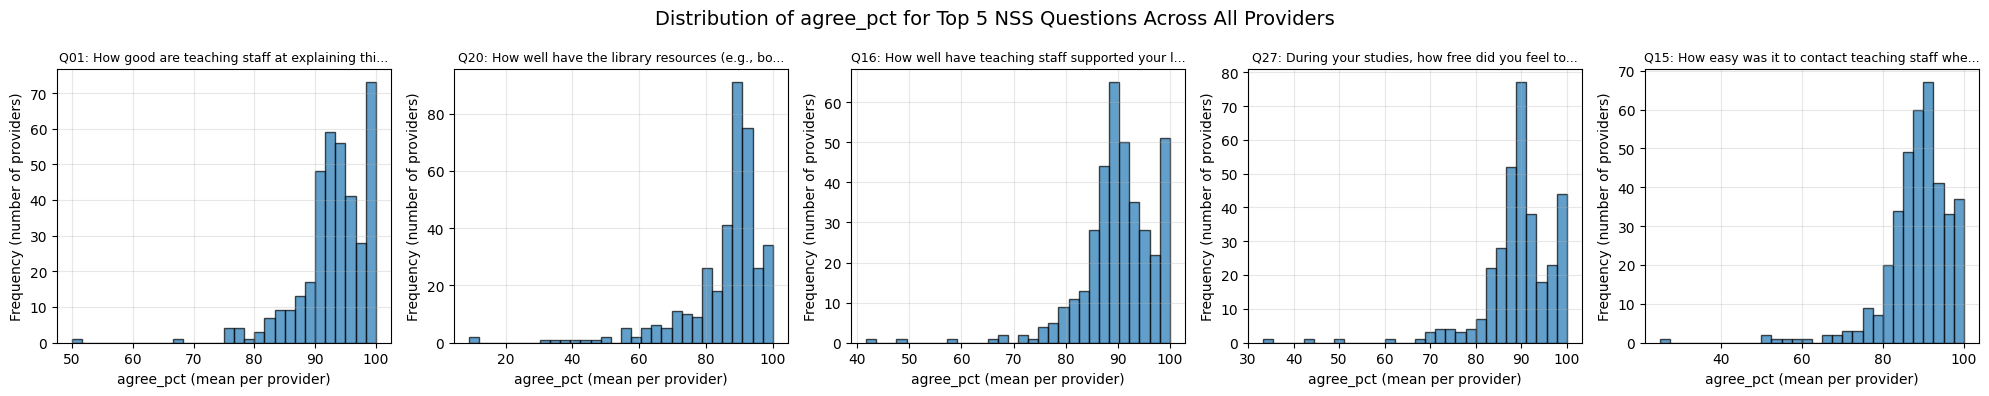

**Your Answer:** Top 5 NSS Questions with mean and standard deviation for **all providers** are:

**[Question, Mean, Standard Deviation]**:

['Q01: How good are teaching staff at explaining things?', 93.19, 5.81]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 85.8, 12.51]
['Q16: How well have teaching staff supported your learning?', 90.13, 7.23]
['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.44, 7.9]
['Q15: How easy was it to contact teaching staff when you needed to?', 88.55, 8.37]


**Your answer appended to `all_answer` dictionary:** <br> [['Q01: How good are teaching staff at explaining things?', 93.19, 5.81], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 85.8, 12.51], ['Q16: How well have teaching staff supported your learning?', 90.13, 7.23], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.44, 7.9], ['Q15: How easy was it to contact teaching staff when you needed to?', 88.55, 8.37]]

In [10]:
# YOUR CODE HERE

# HINT: Use the top 5 questions you found in previous task
# top questions from task 3
top_5_question_texts = [q[0] for q in answer_3]

answer_5 = []

# distribution for each question across all providers
for question_text in top_5_question_texts:
    # Filtering based on the question
    question_data = nss[nss["question"] == question_text]

    # First, calculate mean agree_pct per provider for this question
    provider_means = (
        question_data
        .groupby("provider", as_index=False)  #since we see same question across multiple providers
        .agg(mean_agree_pct=("agree_pct", "mean"))
    )
    #Since the task asks for distribution across providers , provider level means were calculated before computing overall mean and standard deviation

    # calculating mean and standard deviation of provider-level means
    mean_val = provider_means["mean_agree_pct"].mean()
    std_val = provider_means["mean_agree_pct"].std()

    answer_5.append([question_text, round(mean_val, 2), round(std_val, 2)])

# Plot the distributions
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Distribution of agree_pct for Top 5 NSS Questions Across All Providers', fontsize=14)

for idx, question_text in enumerate(top_5_question_texts):
    question_data = nss[nss["question"] == question_text]
    # Calculate mean per provider for plotting
    provider_means = (
        question_data
        .groupby("provider", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
    )
    axes[idx].hist(provider_means["mean_agree_pct"], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_title(question_text[:50] + '...' if len(question_text) > 50 else question_text, fontsize=9)
    axes[idx].set_xlabel('agree_pct (mean per provider)')
    axes[idx].set_ylabel('Frequency (number of providers)')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
#-------- DO NOT CHANGE ---------------
add_to_answer(5, answer_5)
display(Markdown(f"**Your Answer:** Top 5 NSS Questions with mean and standard deviation for **all providers** are:"))
display(Markdown(f"**[Question, Mean, Standard Deviation]**:"))
print("\n".join(str(x) for x in all_answers[5]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[5]}"))

### Task 6: Which 5 NSS questions (`question`) have the **lowest mean** `agree_pct`, regardless of providers, subjects or population. [1.5 Marks]

In [11]:
# YOUR CODE HERE

#Logic same as question 3 except it needs to displayed in ascending order considering lowest mean
# Hence Calculate mean agree_pct for each question across all providers and subjects
question_means = (
    nss
    .groupby("question", as_index=False)
    .agg(mean_agree_pct=("agree_pct", "mean"))
    .sort_values(by="mean_agree_pct", ascending=True)
)

# Get bottom 5 questions (lowest mean)
bottom_5_questions = question_means.head(5)

# Format answer as list of lists
answer_6 = [[row["question"], round(row["mean_agree_pct"], 2)]
            for _, row in bottom_5_questions.iterrows()]
#-------- DO NOT CHANGE ---------------
add_to_answer(6, answer_6)
display(Markdown(f"**Your Answer:** 5 NSS Questions with corresponding lowest mean agree_pct are:"))
print("\n".join(str(x) for x in all_answers[6]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[6]}"))


**Your Answer:** 5 NSS Questions with corresponding lowest mean agree_pct are:

["Q24: How clear is it that students' feedback on the course is acted on?", 68.27]
["Q25: How well does the students' union (association or guild) represent students' academic interests?", 74.84]
['Q14: How often does feedback help you to improve your work?', 75.73]
['Q17: How well organised is your course?', 76.53]
['Q10: How clear were the marking criteria used to assess your work? ', 78.48]


**Your answer appended to `all_answer` dictionary:** <br> [["Q24: How clear is it that students' feedback on the course is acted on?", 68.27], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 74.84], ['Q14: How often does feedback help you to improve your work?', 75.73], ['Q17: How well organised is your course?', 76.53], ['Q10: How clear were the marking criteria used to assess your work? ', 78.48]]

### Task 7: For each of the lowest scoring 5 NSS questions (`question`) identified in Task 6, find 3 providers who have the lowest mean scores (`agree_pct)`. [2.5 Marks]

You need to find 3 providers per NSS question (5 questions), so in total 15 providers.

In [12]:
# YOUR CODE HERE

# HINT: Use the lowest 5 NSS questions you found in Task 6

bottom_5_question_texts = [q[0] for q in answer_6]

answer_7 = []

# For each of the bottom 5 questions, find bottom 3 providers
for question_text in bottom_5_question_texts:
    # Filter data for this question
    question_data = nss[nss["question"] == question_text]

    # Calculate mean agree_pct per provider for this question
    provider_means = (
        question_data
        .groupby("provider", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
        .sort_values(by="mean_agree_pct", ascending=True)
    )

    # Get bottom 3 providers (lowest mean)
    bottom_3_providers = provider_means.head(3)

    # Add to answer list
    for _, row in bottom_3_providers.iterrows():
        answer_7.append([question_text, row["provider"], round(row["mean_agree_pct"], 2)])


#-------- STORE YOUR RESULTS HERE ---------------

## Your answer MUST be list of 15 lists. Each list MUST contain the following items in order ["question" (string), "provider" (string), "mean agree_pct" (float)]
# Your answer must be stored in "answer_7"
# answer_7 = None


#-------- DO NOT CHANGE ---------------
add_to_answer(7, answer_7)
display(Markdown(f"**Your Answer:** 5 NSS Questions with 3 Providers with the corresponding lowest mean agree_pct are:"))
print("\n".join(str(x) for x in all_answers[7]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[7]}"))

**Your Answer:** 5 NSS Questions with 3 Providers with the corresponding lowest mean agree_pct are:

["Q24: How clear is it that students' feedback on the course is acted on?", 'Ballet Theatre UK Limited', 8.3]
["Q24: How clear is it that students' feedback on the course is acted on?", 'Tyne Coast College', 20.0]
["Q24: How clear is it that students' feedback on the course is acted on?", 'Academy of Live Technology Ltd', 22.2]
["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'CWSH, CWS & College of ESPORTS Limited', 18.2]
["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'Lincoln College', 32.15]
["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'Moulton College', 33.3]
['Q14: How often does feedback help you to improve your work?', 'CWSH, CWS & College of ESPORTS Limited', 33.3]
['Q14: How often does feedback help you to improve your work?', 'Wilkes Academy Limited', 43.1]
['Q14: How often does feedback help you to im

**Your answer appended to `all_answer` dictionary:** <br> [["Q24: How clear is it that students' feedback on the course is acted on?", 'Ballet Theatre UK Limited', 8.3], ["Q24: How clear is it that students' feedback on the course is acted on?", 'Tyne Coast College', 20.0], ["Q24: How clear is it that students' feedback on the course is acted on?", 'Academy of Live Technology Ltd', 22.2], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'CWSH, CWS & College of ESPORTS Limited', 18.2], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'Lincoln College', 32.15], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 'Moulton College', 33.3], ['Q14: How often does feedback help you to improve your work?', 'CWSH, CWS & College of ESPORTS Limited', 33.3], ['Q14: How often does feedback help you to improve your work?', 'Wilkes Academy Limited', 43.1], ['Q14: How often does feedback help you to improve your work?', 'The Film Education Training Trust Limited', 43.8], ['Q17: How well organised is your course?', 'The Film Education Training Trust Limited', 6.3], ['Q17: How well organised is your course?', 'CWSH, CWS & College of ESPORTS Limited', 8.3], ['Q17: How well organised is your course?', 'New Model Institute for Technology and Engineering', 15.8], ['Q10: How clear were the marking criteria used to assess your work? ', 'Beat Media Group Limited', 10.0], ['Q10: How clear were the marking criteria used to assess your work? ', 'The Film Education Training Trust Limited', 15.6], ['Q10: How clear were the marking criteria used to assess your work? ', 'Royal Academy of Dance', 35.0]]

### Task 8: For the lowest scoring 5 NSS questions identified in Task 6 , for each `question` calculate the distribution (mean and standard deviation) for **all providers**, and plot the 5 distributions (i.e., one distribution for each NSS question). [4 Marks]

You need to calculate 5 distributions across all providers for the lowest scoring 5 NSS questions.

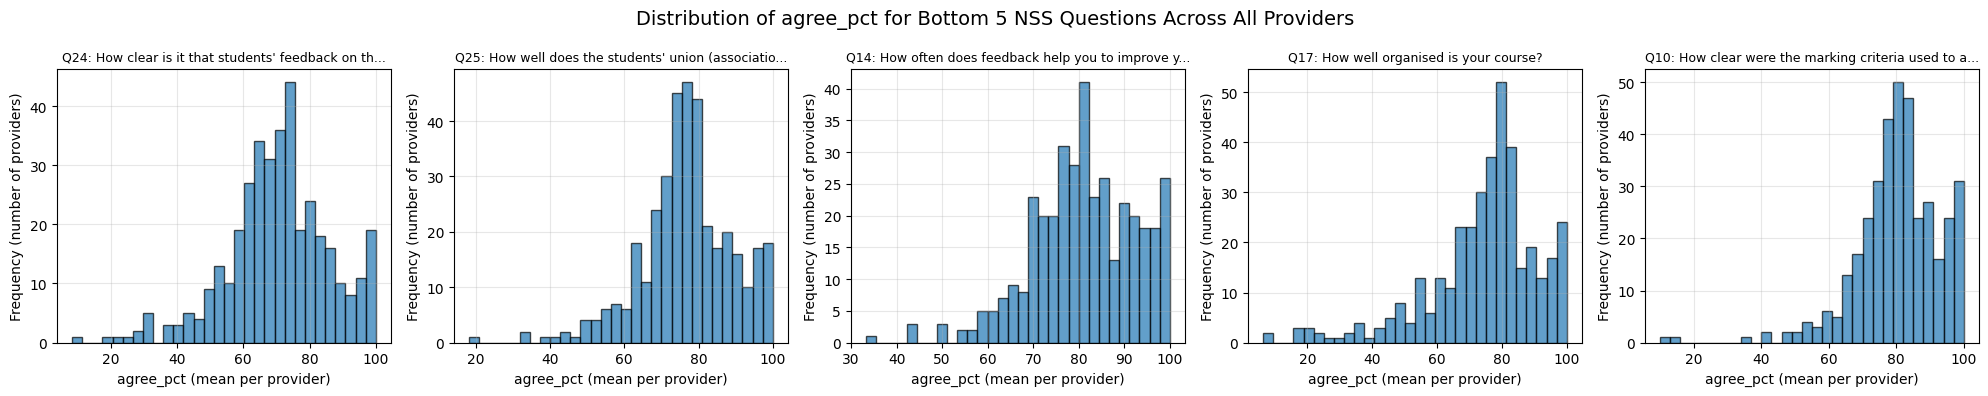

**Your Answer:** 5 NSS Questions with the lowest mean and standard deviation for **all providers** are:

**[Question, Mean, Standard Deviation]**:

["Q24: How clear is it that students' feedback on the course is acted on?", 70.39, 15.61]
["Q25: How well does the students' union (association or guild) represent students' academic interests?", 76.81, 12.59]
['Q14: How often does feedback help you to improve your work?', 80.98, 11.62]
['Q17: How well organised is your course?', 74.2, 17.31]
['Q10: How clear were the marking criteria used to assess your work? ', 80.48, 12.58]


**Your answer appended to `all_answer` dictionary:** <br> [["Q24: How clear is it that students' feedback on the course is acted on?", 70.39, 15.61], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 76.81, 12.59], ['Q14: How often does feedback help you to improve your work?', 80.98, 11.62], ['Q17: How well organised is your course?', 74.2, 17.31], ['Q10: How clear were the marking criteria used to assess your work? ', 80.48, 12.58]]

In [13]:
# YOUR CODE HERE
# HINT: Use the bottom 5 questions you found in Task 6
bottom_5_question_texts = [q[0] for q in answer_6]

answer_8 = []

# Calculate distribution for each question across all providers
for question_text in bottom_5_question_texts:
    # Filter data for this question
    question_data = nss[nss["question"] == question_text]

    # First, calculate mean agree_pct per provider for this question
    provider_means = (
        question_data
        .groupby("provider", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
    )

    # Then calculate mean and standard deviation of provider-level means
    mean_val = provider_means["mean_agree_pct"].mean()
    std_val = provider_means["mean_agree_pct"].std()

    answer_8.append([question_text, round(mean_val, 2), round(std_val, 2)])

# Plot the distributions
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Distribution of agree_pct for Bottom 5 NSS Questions Across All Providers', fontsize=14)

for idx, question_text in enumerate(bottom_5_question_texts):
    question_data = nss[nss["question"] == question_text]
    # Calculate mean per provider for plotting
    provider_means = (
        question_data
        .groupby("provider", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
    )
    axes[idx].hist(provider_means["mean_agree_pct"], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_title(question_text[:50] + '...' if len(question_text) > 50 else question_text, fontsize=9)
    axes[idx].set_xlabel('agree_pct (mean per provider)')
    axes[idx].set_ylabel('Frequency (number of providers)')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#-------- DO NOT CHANGE ---------------
add_to_answer(8, answer_8)
display(Markdown(f"**Your Answer:** 5 NSS Questions with the lowest mean and standard deviation for **all providers** are:"))
display(Markdown(f"**[Question, Mean, Standard Deviation]**:"))
print("\n".join(str(x) for x in all_answers[8]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[8]}"))

### Task 9: Calculate the total number of students for each providers identified in Task 4. [2 Marks]

In Task 4, for each of the top 5 NSS questions, you found 3 providers with highest mean `agree_pct`. What are the total number of undergraduate students (`population`) at each provider? Given 15 providers, you answer will have 15 populations.

In [14]:
# YOUR CODE HERE

# HINT: Use the 15 providers you identified in Task 4
# HINT: TAKE THE SUM OF UNIQUE VALUES IN POPULATIONS for a given provider
providers_from_task4 = list(set([item[1] for item in answer_4]))

answer_9 = []

# Calculate total population for each provider
for provider in providers_from_task4:
    provider_data = nss[nss["provider"] == provider]
    # Sum unique population values
    total_pop = sum(set(provider_data["population"]))
    answer_9.append([provider, int(total_pop)])

# Sort by provider name for consistency
answer_9.sort(key=lambda x: x[0])

#-------- DO NOT CHANGE ---------------
add_to_answer(9, answer_9)
display(Markdown(f"**Your Answer:** for each of the top 5 NSS questions, the sum of unique populations for the top 3 providers with the highest mean `agree_pct` are:"))
print("\n".join(str(x) for x in all_answers[9]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[9]}"))


**Your Answer:** for each of the top 5 NSS questions, the sum of unique populations for the top 3 providers with the highest mean `agree_pct` are:

['Amity Global Education Ltd', 31]
['Assemblies of God Incorporated', 16]
['Barnet & Southgate College', 29]
['Beat Media Group Limited', 17]
['Bury College', 16]
['Dancebox Theatre Works', 13]
['Drama Studio London Limited', 37]
['Slough Borough Council', 21]
['Spirit SSR Limited', 31]
['The Cambridge Theological Federation', 19]
['The Engineering and Design Institute London', 34]
['The London Interdisciplinary School Ltd', 3]
['The Markfield Institute of Higher Education', 34]
['The Windsor Forest Colleges Group', 24]
['Trinity College (Bristol) Limited', 15]


**Your answer appended to `all_answer` dictionary:** <br> [['Amity Global Education Ltd', 31], ['Assemblies of God Incorporated', 16], ['Barnet & Southgate College', 29], ['Beat Media Group Limited', 17], ['Bury College', 16], ['Dancebox Theatre Works', 13], ['Drama Studio London Limited', 37], ['Slough Borough Council', 21], ['Spirit SSR Limited', 31], ['The Cambridge Theological Federation', 19], ['The Engineering and Design Institute London', 34], ['The London Interdisciplinary School Ltd', 3], ['The Markfield Institute of Higher Education', 34], ['The Windsor Forest Colleges Group', 24], ['Trinity College (Bristol) Limited', 15]]

### Task 10: What 5 broad subjects (`cah1_subject`) are the most popular (i.e., have the highest `population`) across all providers? [2.5 Mark]

In [15]:
# YOUR CODE HERE
# HINT: You MUST TAKE THE SUM OF UNIQUE VALUES IN POPULATION FOR A GIVEN CAH1_SUBJECT
subject_pop = (
    nss
    .groupby("cah1_subject", as_index=False)
    .agg(sum_population=("population", lambda x: sum(set(x))))
    .sort_values(by="sum_population", ascending=False)
)

# retrive top 5 subjects
top_5_subjects = subject_pop.head(5)

# Format answer as list of lists
answer_10 = [[row["cah1_subject"], int(row["sum_population"])]
              for _, row in top_5_subjects.iterrows()]

#-------- DO NOT CHANGE ---------------
add_to_answer(10, answer_10)
display(Markdown(f"**Your Answer:** The top 5 `cah1_subject`, and their respective populations are:"))
print("\n".join(str(x) for x in all_answers[10]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[10]}"))

**Your Answer:** The top 5 `cah1_subject`, and their respective populations are:

['business and management', 51232]
['social sciences', 26742]
['design, and creative and performing arts', 25572]
['subjects allied to medicine', 24809]
['law', 19648]


**Your answer appended to `all_answer` dictionary:** <br> [['business and management', 51232], ['social sciences', 26742], ['design, and creative and performing arts', 25572], ['subjects allied to medicine', 24809], ['law', 19648]]

### Task 11: For the 5 most popular broad subjects (`cah1_subject`) as calculated in Task 10, what 3 NSS questions have the highest mean `agree_pct`? [3.5 Marks]

For each of the 5 providers, you will have 3 nss questions so in total 15 questions.

In [16]:
# YOUR CODE HERE

# HINT: use the 5 most popular subjects that you identified in Task 10
top_5_subjects = [s[0] for s in answer_10]

answer_11 = []

# For each of the 5 most popular subjects, find top 3 NSS questions
for subject in top_5_subjects:
    # Filter data for this subject
    subject_data = nss[nss["cah1_subject"] == subject]

    # Calculate mean agree_pct per question for this subject
    question_means = (
        subject_data
        .groupby("question", as_index=False)
        .agg(mean_agree_pct=("agree_pct", "mean"))
        .sort_values(by="mean_agree_pct", ascending=False)
    )

    # Get top 3 questions
    top_3_questions = question_means.head(3)

    # Add to answer list
    for _, row in top_3_questions.iterrows():
        answer_11.append([subject, row["question"], round(row["mean_agree_pct"], 2)])
#-------- STORE YOUR RESULTS HERE ---------------

#-------- DO NOT CHANGE ---------------
add_to_answer(11, answer_11)
display(Markdown(f"**Your Answer:** For the top 5 subjects, the top 3 questions with the corresponding highest mean agree_pct are:"))
print("\n".join(str(x) for x in all_answers[11]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[11]}"))



**Your Answer:** For the top 5 subjects, the top 3 questions with the corresponding highest mean agree_pct are:

['business and management', 'Q01: How good are teaching staff at explaining things?', 92.31]
['business and management', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.72]
['business and management', 'Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.68]
['social sciences', 'Q01: How good are teaching staff at explaining things?', 93.68]
['social sciences', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 90.84]
['social sciences', 'Q16: How well have teaching staff supported your learning?', 88.63]
['design, and creative and performing arts', 'Q01: How good are teaching staff at explaining things?', 92.35]
['design, and creative and performing arts', 'Q16: How well have teaching staff supported your learning?', 89.41]
['design, and creative and performing arts', 'Q15: How easy was it to conta

**Your answer appended to `all_answer` dictionary:** <br> [['business and management', 'Q01: How good are teaching staff at explaining things?', 92.31], ['business and management', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.72], ['business and management', 'Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.68], ['social sciences', 'Q01: How good are teaching staff at explaining things?', 93.68], ['social sciences', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 90.84], ['social sciences', 'Q16: How well have teaching staff supported your learning?', 88.63], ['design, and creative and performing arts', 'Q01: How good are teaching staff at explaining things?', 92.35], ['design, and creative and performing arts', 'Q16: How well have teaching staff supported your learning?', 89.41], ['design, and creative and performing arts', 'Q15: How easy was it to contact teaching staff when you needed to?', 88.53], ['subjects allied to medicine', 'Q01: How good are teaching staff at explaining things?', 92.42], ['subjects allied to medicine', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 91.11], ['subjects allied to medicine', 'Q09: How well has your course developed your knowledge and skills that you think you will need for your future?', 88.66], ['law', 'Q01: How good are teaching staff at explaining things?', 92.64], ['law', 'Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 90.3], ['law', 'Q21: How easy is it to access subject specific resources (e.g., equipment, facilities, software) when you need them?', 89.32]]

### Task 12: Which 5 subjects (`cah3_subject`) have the highest mean score (`agree_pct`) for **all** NSS Questions? [3 Mark]

For each subject, you will need to find the mean `agree_pct` across **all** NSS questions for that subject.

In [17]:
# YOUR CODE HERE
# Calculate mean agree_pct for each cah3_subject across all NSS questions
subject_means = (
    nss
    .groupby("cah3_subject", as_index=False)
    .agg(mean_agree_pct=("agree_pct", "mean"))
    .sort_values(by="mean_agree_pct", ascending=False)
)

# Get top 5 subjects
top_5_subjects = subject_means.head(5)

# Format answer as list of lists
answer_12 = [[row["cah3_subject"], round(row["mean_agree_pct"], 2)]
              for _, row in top_5_subjects.iterrows()]
#-------- STORE YOUR RESULTS HERE ---------------

## Your answer MUST be list of 5 lists. Each list MUST contain the following items in order ["cah3_subject" (string), "mean agree_pct" (float)]
# Your answer must be stored in "answer_12"
# answer_12 = None


#-------- DO NOT CHANGE ---------------
add_to_answer(12, answer_12)
display(Markdown(f"**Your Answer:** For the top 5 specific subjects (cah3_subject), the corresponding mean `agree_pct` across all questions are:"))
print("\n".join(str(x) for x in all_answers[12]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[12]}"))

**Your Answer:** For the top 5 specific subjects (cah3_subject), the corresponding mean `agree_pct` across all questions are:

['Welsh studies', 96.22]
['others in Celtic studies', 91.95]
['heritage studies', 91.31]
['childhood and youth studies', 90.12]
['food and beverage studies (non-specific)', 90.12]


**Your answer appended to `all_answer` dictionary:** <br> [['Welsh studies', 96.22], ['others in Celtic studies', 91.95], ['heritage studies', 91.31], ['childhood and youth studies', 90.12], ['food and beverage studies (non-specific)', 90.12]]

### Task 13: Choose a broad subject (`cha1_subject`) [0.5 Mark]

We have guided you through the questions and exploring the NSS dataset in the above task so far.

You may wish to explore the dataset further now to decide which broad subject (or discipline) you would like to recommend based on your reasoning and findings in the dataset.

If needed, you can add new code and/or text cells.

In [18]:
# Task 13: Choose a broad subject (CAH1)
#recommending based on population and mean satisfaction
# 1. Summarising each broad subject
subject_summary = (
    nss
    .groupby("cah1_subject", as_index=False)
    .agg(
        total_population=("population", lambda x: sum(set(x))),
        mean_satisfaction=("agree_pct", "mean")
    )
    .sort_values("total_population", ascending=False)
)

# Displaying top subjects
display(subject_summary.head(5))

# 2. From looks of it , choosing Business and Management (highest demand, good satisfaction) as shown below
answer_13 = "business and management"
"""
High population: In the NSS data, “business and management” has one of the largest total populations among CAH1 subjects, which indicates strong demand and commercial viability (more students, more market size).
​
Good satisfaction: Its mean agree_pct (satisfaction) is also relatively high compared with other large-population subjects, so it does not trade demand for poor student experience.
​​"""
#-------- DO NOT CHANGE ---------------
add_to_answer(13, answer_13)

display(Markdown(f"**Your Answer:** You have chosen : {all_answers[13]}"))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[13]}"))

,cah1_subject,total_population,mean_satisfaction
3,business and management,51232,84.692886
18,social sciences,26742,84.181462
6,"design, and creative and performing arts",25572,82.308963
19,subjects allied to medicine,24809,82.803161
12,law,19648,82.217413


**Your Answer:** You have chosen : business and management

**Your answer appended to `all_answer` dictionary:** <br> business and management

### Task 14:  Choose a subject (`cah3_subject`) within your chosen broad subject (`cah1_subject`) [0.5 Mark]

You need to explore what subjects (`cah3_subject`) within your chosen broad subject (`cah1_subject`) are available and based on your analyses, recommend your specfic subject (`cah3_subject`).

If needed, you can add new code and/or text cells.

In [19]:
# 1. Filter to chosen broad subject (as stored in dataset)
chosen_cah1_subject = "business and management"
bm_data = nss[nss["cah1_subject"] == chosen_cah1_subject]

# 2. Explore CAH3 subjects correctly
cah3_summary = (
    bm_data
    .groupby("cah3_subject", as_index=False)
    .agg(
        total_population=("population", lambda x: sum(set(x))),
        mean_satisfaction=("agree_pct", "mean"),
        num_providers=("provider", "nunique")
    )
    .sort_values("total_population", ascending=False)
)

# 3. Display results
display(
    cah3_summary[
        ["cah3_subject", "total_population", "mean_satisfaction", "num_providers"]
    ]
)

# 4. Excluding non-programme categories
valid_subjects = cah3_summary[
    ~cah3_summary["cah3_subject"].str.contains("non-specific|others", case=False)
]

# 5. selecting subject
chosen_cah3_subject = valid_subjects.iloc[0]["cah3_subject"]

print(f"Chosen CAH3 subject: {chosen_cah3_subject}")

# -------- STORE YOUR RESULTS HERE ---------------
answer_14 = chosen_cah3_subject

#Here although we see Business and Management tops the list but final decision has been made on no.of providers.
#

#-------- DO NOT CHANGE ---------------
## DO NOT Change - Formatted answer and appending them to all answers
add_to_answer(14, answer_14)
display(Markdown(f"**Your Answer:** You have chose : {all_answers[14]}"))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[14]}"))

,cah3_subject,total_population,mean_satisfaction,num_providers
1,business and management (non-specific),18920,85.424228,96
2,business studies,18102,84.753981,127
5,management studies,7636,83.750553,77
0,accounting,6244,85.418034,107
6,marketing,5707,82.800799,102
3,finance,5678,84.244518,101
8,"tourism, transport and travel",4920,86.545335,79
4,human resource management,621,84.268519,38
7,others in business and management,60,89.705185,5


Chosen CAH3 subject: business studies


**Your Answer:** You have chose : business studies

**Your answer appended to `all_answer` dictionary:** <br> business studies

### Task 15: For your chosen `chosen_cha3_subject`, what are the top 5 NSS questions with the highest mean `agree_pct` across all providers but excluding your employer? [4 Marks]

In [20]:
# Filter for chosen subject and exclude employer
subject_data = nss[
    (nss["cah3_subject"] == chosen_cah3_subject) &
    (nss["provider"] != employer_name)
]

# Step 1: Provider-level mean per question
provider_question_means = (
    subject_data
    .groupby(["question", "provider"], as_index=False)
    .agg(mean_agree_pct=("agree_pct", "mean"))
)

# Step 2: Mean across providers
question_means = (
    provider_question_means
    .groupby("question", as_index=False)
    .agg(mean_agree_pct=("mean_agree_pct", "mean"))
    .sort_values(by="mean_agree_pct", ascending=False)
)

# Top 5 questions
top_5_questions = question_means.head(5)

# Format answer
answer_15 = [
    [row["question"], round(row["mean_agree_pct"], 2)]
    for _, row in top_5_questions.iterrows()
]
chosen_cha3_subject = chosen_cah3_subject


add_to_answer(15, answer_15)
display(Markdown(f"**Your Answer:** For {chosen_cha3_subject} subject, the corresponding 5 NSS questions with the highest mean `agree_pct` are:"))
print("\n".join(str(x) for x in all_answers[15]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[15]}"))


**Your Answer:** For business studies subject, the corresponding 5 NSS questions with the highest mean `agree_pct` are:

['Q01: How good are teaching staff at explaining things?', 92.1]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 90.75]
['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.69]
['Q21: How easy is it to access subject specific resources (e.g., equipment, facilities, software) when you need them?', 88.89]
['Q16: How well have teaching staff supported your learning?', 88.74]


**Your answer appended to `all_answer` dictionary:** <br> [['Q01: How good are teaching staff at explaining things?', 92.1], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 90.75], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 89.69], ['Q21: How easy is it to access subject specific resources (e.g., equipment, facilities, software) when you need them?', 88.89], ['Q16: How well have teaching staff supported your learning?', 88.74]]

### Task 16: What are the NSS question scores (`agree_pct`) for your employer across all subjects (`cah3_subject)`? [2 Marks]

As an approximate and comparative measure to your findings in Task 15, you need to explore your employer's NSS question score (`agree_pct`) across all all subjects (`cah3_subject)`

In [21]:
# YOUR CODE HERE
# HINT: TAKE THE SUM OF UNIQUE VALUES IN POPULATION FOR A GIVEN CAH3_SUBJECT

# HINT: This is already initialised to "University of Southampton"
employer_name = employer_name
employer_data = nss[nss["provider"] == employer_name]

# Calculate mean agree_pct for each question across all subjects for the employer
question_means = (
    employer_data
    .groupby("question", as_index=False)
    .agg(mean_agree_pct=("agree_pct", "mean"))
    .sort_values(by="mean_agree_pct", ascending=False)
)

# Format answer as list of lists (all questions, not just top 5)
answer_16 = [[row["question"], round(row["mean_agree_pct"], 2)]
              for _, row in question_means.iterrows()]

#-------- DO NOT CHANGE ---------------
add_to_answer(16, answer_16)
display(Markdown(f"**Your Answer:** For {employer_name}, the corresponding NSS questions with the highest mean `agree_pct` are:"))
print("\n".join(str(x) for x in all_answers[16]))
display(Markdown(f"**Your answer appended to `all_answer` dictionary:** <br> {all_answers[16]}"))

**Your Answer:** For University of Southampton, the corresponding NSS questions with the highest mean `agree_pct` are:

['Q01: How good are teaching staff at explaining things?', 93.08]
['Q15: How easy was it to contact teaching staff when you needed to?', 89.58]
['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.26]
['Q21: How easy is it to access subject specific resources (e.g., equipment, facilities, software) when you need them?', 88.5]
['Q16: How well have teaching staff supported your learning?', 88.44]
['Q05: To what extent have you had the chance to explore ideas and concepts in depth? ', 88.3]
['Q19: How well have the IT resources and facilities supported your learning?', 88.2]
['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 88.09]
['Q03: How often is the course intellectually stimulating?', 87.97]
['Q22: To what extent do you get the right opportunities to give feedback on your course?', 86.97]
['Q04: How often does your course challenge you to achieve your best work?', 8

**Your answer appended to `all_answer` dictionary:** <br> [['Q01: How good are teaching staff at explaining things?', 93.08], ['Q15: How easy was it to contact teaching staff when you needed to?', 89.58], ['Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?', 89.26], ['Q21: How easy is it to access subject specific resources (e.g., equipment, facilities, software) when you need them?', 88.5], ['Q16: How well have teaching staff supported your learning?', 88.44], ['Q05: To what extent have you had the chance to explore ideas and concepts in depth? ', 88.3], ['Q19: How well have the IT resources and facilities supported your learning?', 88.2], ['Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?', 88.09], ['Q03: How often is the course intellectually stimulating?', 87.97], ['Q22: To what extent do you get the right opportunities to give feedback on your course?', 86.97], ['Q04: How often does your course challenge you to achieve your best work?', 86.94], ['Q07: To what extent have you had the chance to bring together information and ideas from different topics?', 84.49], ['Q09: How well has your course developed your knowledge and skills that you think you will need for your future?', 84.42], ['Q06: How well does your course introduce subjects and skills in a way that builds on what you have already learned?', 84.09], ['Q13: How often have you received assessment feedback on time?', 83.23], ["Q26: How well communicated was information about your university/college's mental wellbeing support services?", 82.68], ['Q18: How well were any changes to teaching on your course communicated?', 82.55], ['Q11: How fair has the marking and assessment been on your course? ', 82.01], ['Q12: How well have assessments allowed you to demonstrate what you have learned?', 81.85], ['Q17: How well organised is your course?', 81.45], ["Q23: To what extent are students' opinions about the course valued by staff?", 81.3], ['Q02: How often do teaching staff make the subject engaging?', 79.34], ['Q08: To what extent does your course have the right balance of directed and independent study?', 78.59], ["Q25: How well does the students' union (association or guild) represent students' academic interests?", 76.71], ['Q10: How clear were the marking criteria used to assess your work? ', 71.89], ['Q14: How often does feedback help you to improve your work?', 69.42], ["Q24: How clear is it that students' feedback on the course is acted on?", 65.37]]

### Section (e): Saving Your Answers to a JSON File

The code below will save your answers to a json file and prints out the answers.

In [22]:
# DOUBLE CHECK ALL YOUR ANSWERS

#To save your answers to a json file - this should be created in your current directory
with open("all_answers.json", "w") as f:
    json.dump(all_answers, f)
    display(Markdown(f"## Your answers have been saved to `all_answer.json` file successfully!"))


#Finally, open all_answers.json file to check  to ensure it has the correctly formatted answers
#If you are satisfied with it then submit all_answer.json file along with this notebook (.ipynb format)

# --- Load JSON file ---
with open("all_answers.json", "r") as f:
    all_answers = json.load(f)

# --- Display in readable plain-text format ---
display(Markdown(f"## Your saved answers :"))

for key, value in all_answers.items():
    if isinstance(value, list):
        print(f"{key}: [")
        for item in value:
            if isinstance(item, list):
                print(f"   [{', '.join(str(x) for x in item)}]")
            else:
                print(f"   {item}")
        print("]")
    else:
        print(f"{key}: {value}")
    print()


## Your answers have been saved to `all_answer.json` file successfully!

## Your saved answers :

1: 35

2: [
   history
   344
]

3: [
   [Q01: How good are teaching staff at explaining things?, 92.85]
   [Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?, 89.66]
   [Q16: How well have teaching staff supported your learning?, 88.93]
   [Q27: During your studies, how free did you feel to express your ideas, opinions, and beliefs?, 88.71]
   [Q15: How easy was it to contact teaching staff when you needed to?, 88.36]
]

4: [
   [Q01: How good are teaching staff at explaining things?, Amity Global Education Ltd, 100.0]
   [Q01: How good are teaching staff at explaining things?, Assemblies of God Incorporated, 100.0]
   [Q01: How good are teaching staff at explaining things?, Spirit SSR Limited, 100.0]
   [Q20: How well have the library resources (e.g., books, online services and learning spaces) supported your learning?, Trinity College (Bristol) Limited, 100.0]
   [Q20: How well have the library resources (e.g., books